# Employee Training & Adoption Analysis
Independent OCM portfolio demonstration using 100 synthetic employee records. Objective: identify training gaps and recommend change support.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("employee_training.csv")
df.head()

,employee_id,department,pre_score,completed,post_score,adopted
0,E001,Finance,43,True,57.0,True
1,E002,Finance,67,True,89.0,False
2,E003,Finance,63,True,71.0,True
3,E004,Finance,55,True,79.0,True
4,E005,Finance,55,True,72.0,True


## Training and adoption KPIs

In [2]:
paired = df.dropna(subset=["post_score"])
print(f"Training completion: {df.completed.mean():.1%}")
print(f"Adoption: {df.adopted.mean():.1%}")
print(f"Average learning gain: {(paired.post_score - paired.pre_score).mean():.1f} points")

Training completion: 91.0%
Adoption: 82.0%
Average learning gain: 16.2 points


## Training effectiveness
Compare the same employees before and after training.

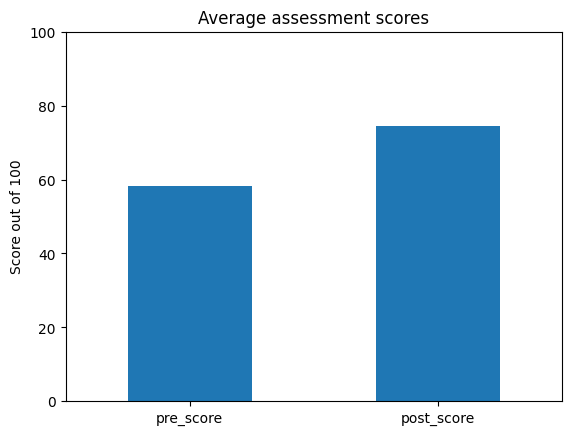

In [3]:
paired[["pre_score", "post_score"]].mean().plot.bar(title="Average assessment scores", rot=0)
plt.ylabel("Score out of 100")
plt.ylim(0, 100)
plt.show()

## Department comparison

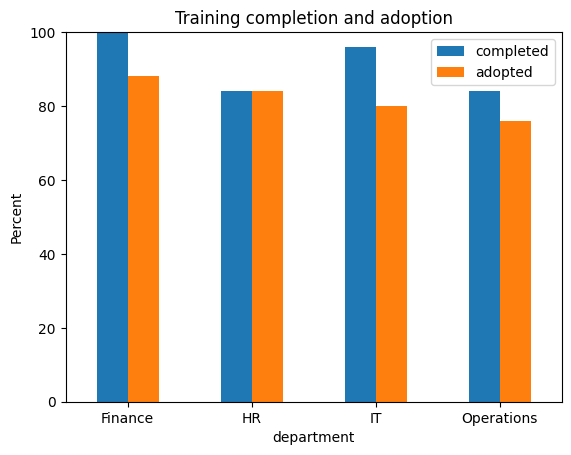

,completed,adopted
department,,
Finance,100.0,88.0
HR,84.0,84.0
IT,96.0,80.0
Operations,84.0,76.0


In [4]:
summary = df.groupby("department")[["completed", "adopted"]].mean() * 100
summary.plot.bar(title="Training completion and adoption", rot=0)
plt.ylabel("Percent")
plt.ylim(0, 100)
plt.show()
summary.round(1)

## OCM action plan

In [5]:
print("Lowest completion:", summary.completed.idxmin())
print("Lowest adoption:", summary.adopted.idxmin())
print("Employees needing training:", (~df.completed).sum())
print("Completed but not adopted:", (df.completed & ~df.adopted).sum())

Lowest completion: HR
Lowest adoption: Operations
Employees needing training: 9
Completed but not adopted: 13


## Recommendations
- Prioritize training reminders and manager support in the lowest-completion department.
- Offer office hours to trained employees who have not adopted the platform.
- Repeat assessments and usage tracking after two weeks.

Limitations: synthetic single-snapshot data; observed differences do not establish causal effects of training.